# SARIMA для аналізу попиту

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

In [1]:
import os
import sys
import django

sys.path.append(r"C:\Diploma\backend")

os.environ.setdefault("DJANGO_SETTINGS_MODULE", "config.settings")
os.environ["DJANGO_ALLOW_ASYNC_UNSAFE"] = "true"

django.setup()

In [3]:
from django.db.models import Count
from django.db.models.functions import TruncMonth

from main.models import Records

### Формування ряду попиту

In [4]:
records_by_month = (
    Records.objects
    .filter(status="завершено")
    .annotate(month=TruncMonth("date_time"))
    .values("month")
    .annotate(count=Count("id_record"))
    .order_by("month")
)

month_labels = [
    item["month"].strftime("%Y-%m")
    for item in records_by_month
]

month_counts = [
    item["count"]
    for item in records_by_month
]

ts = pd.Series(
    month_counts,
    index=pd.to_datetime(month_labels)
)

ts = ts.asfreq("MS")

### Візуалізація часового ряду

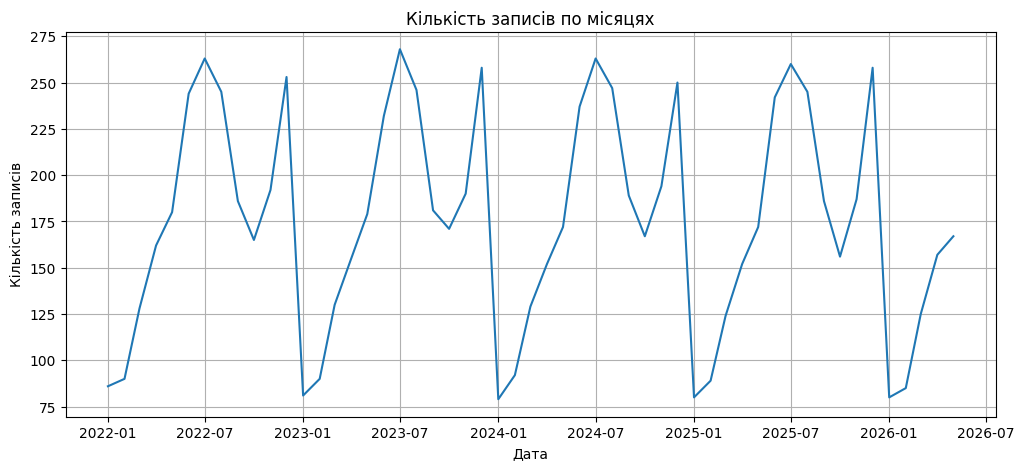

In [5]:
plt.figure(figsize=(12,5))

plt.plot(ts)

plt.title("Кількість записів по місяцях")
plt.xlabel("Дата")
plt.ylabel("Кількість записів")

plt.grid(True)

plt.show()

Візуальний аналіз часового ряду показав наявність вираженої річної сезонності з періодом 12 місяців. Кількість записів клієнтів демонструє регулярне зростання в літні місяці та зниження на початку календарного року.

### Перевірка стаціонарності (ADF)

In [6]:
result = adfuller(ts.dropna())

print("ADF statistic:", result[0])
print("p-value:", result[1])

ADF statistic: -1.1402622698507612
p-value: 0.6987517454730668


Результати тесту Дікі-Фуллера показали значення p-value = 0.699, що перевищує рівень значущості 0.05. Це свідчить про нестаціонарність початкового ряду та необхідність застосування диференціювання.

### Диференціювання

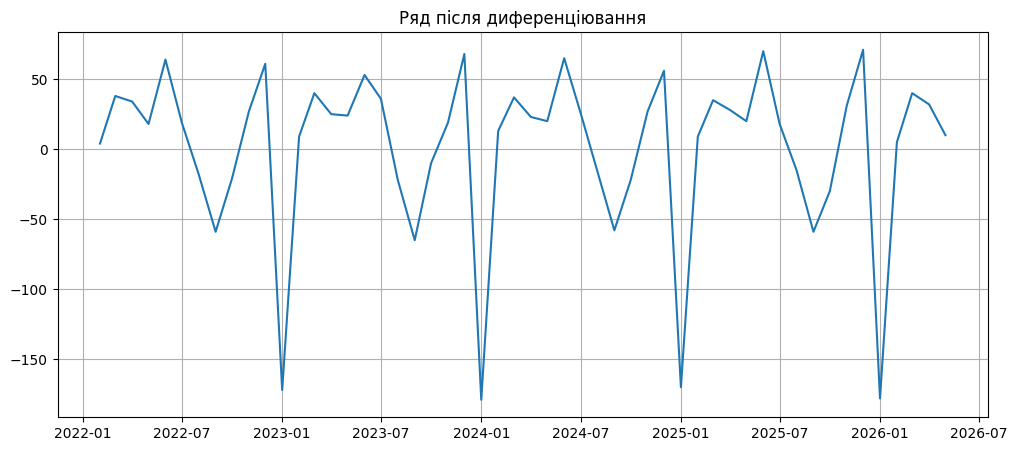

In [7]:
ts_diff = ts.diff().dropna()

plt.figure(figsize=(12,5))
plt.plot(ts_diff)
plt.title("Ряд після диференціювання")
plt.grid(True)
plt.show()

Для усунення нестаціонарності було виконано диференціювання першого порядку. Після перетворення коливання ряду стали більш стабільними відносно середнього значення.

### ACF

<Figure size 1000x500 with 0 Axes>

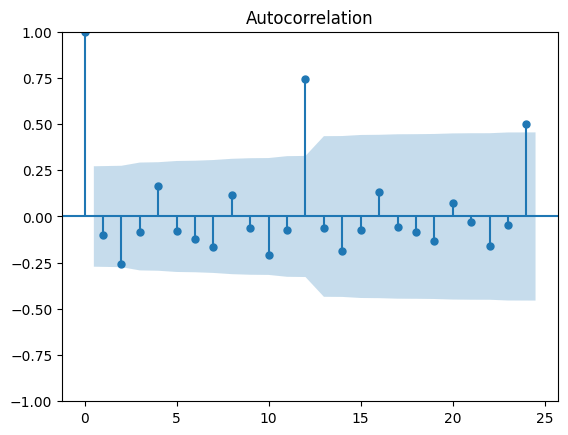

In [8]:
plt.figure(figsize=(10,5))

plot_acf(
    ts_diff,
    lags=24
)

plt.show()

На графіку ACF спостерігаються значущі піки на лагах 12 та 24, що підтверджує наявність річної сезонності.

### PACF

<Figure size 1000x500 with 0 Axes>

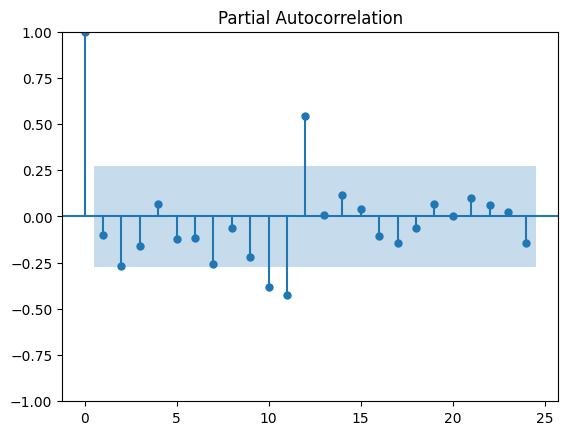

In [9]:
plt.figure(figsize=(10,5))

plot_pacf(
    ts_diff,
    lags=24
)

plt.show()

На графіку PAKF можна спостерігати дуже сильний пік (lag=12), що свідчить про те що сезонна авторегресійна складова присутня.Тобто модель повинна враховувати сезонний AR-компонент.

In [10]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
candidates = [
    ((1, 1, 0), (1, 1, 0, 12)),
    ((1, 1, 1), (1, 1, 0, 12)),
    ((1, 1, 0), (1, 1, 1, 12)),
    ((1, 1, 1), (1, 1, 1, 12)),
    ((0, 1, 1), (1, 1, 1, 12)),
]

results = []

for order, seasonal_order in candidates:
    model = SARIMAX(
        ts,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fit = model.fit(disp=False)

    results.append({
        "order": order,
        "seasonal_order": seasonal_order,
        "AIC": fit.aic
    })

pd.DataFrame(results).sort_values("AIC")

,order,seasonal_order,AIC
4,"(0, 1, 1)","(1, 1, 1, 12)",162.190327
3,"(1, 1, 1)","(1, 1, 1, 12)",163.789404
1,"(1, 1, 1)","(1, 1, 0, 12)",167.194562
0,"(1, 1, 0)","(1, 1, 0, 12)",178.151153
2,"(1, 1, 0)","(1, 1, 1, 12)",180.105232


Отже, обираємо такі параметри моделі (0,1,1)(1,1,1)12, так як коефіціент Акайке найнижчий. Тепер перевіримо наскільки точним буде прогноз.

In [11]:
train = ts[:-12]
test = ts[-12:]

In [12]:
model = SARIMAX(
    train,
    order=(0,1,1),
    seasonal_order=(1,1,1,12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

fit = model.fit(disp=False)

c:\Diploma\backend\venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


In [13]:
forecast = fit.forecast(steps=12)

In [14]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(test, forecast)

rmse = mean_squared_error(
    test,
    forecast
) ** 0.5

r2 = r2_score(
    test,
    forecast
)

print("MAE =", mae)
print("RMSE =", rmse)
print("R² =", r2)

MAE = 5.160418722471136
RMSE = 6.391237678860926
R² = 0.9888469845548965


In [15]:
import numpy as np

mape = np.mean(
    np.abs((test - forecast) / test)
) * 100

print("MAPE =", mape, "%")

MAPE = 3.0738866958562556 %


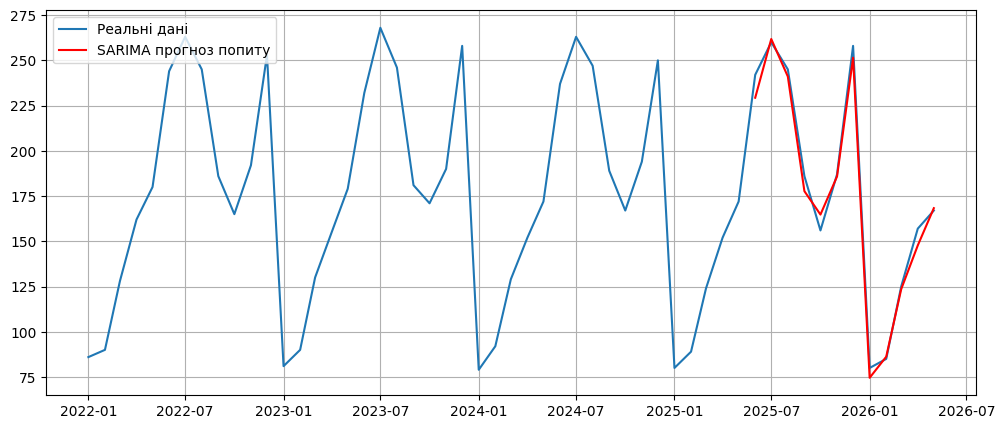

In [16]:
plt.figure(figsize=(12,5))

plt.plot(ts.index, ts, label="Реальні дані")

plt.plot(
    forecast.index,
    forecast,
    label="SARIMA прогноз попиту",
    color="red"
)

plt.legend()
plt.grid(True)
plt.show()

Для оцінки якості прогнозування було використано тестову вибірку, що містить останні 12 місяців спостережень. Отримана модель SARIMA продемонструвала високу точність прогнозування: MAE = 5.16, RMSE = 6.39, MAPE = 3.07% та коефіцієнт детермінації R² = 0.989. Значення MAPE менше 10% свідчить про високу точність прогнозу, а значення R², близьке до 1, підтверджує здатність моделі адекватно описувати закономірності часового ряду.

# SARIMA для аналізу доходів

In [34]:
from django.db.models import Sum, F, DecimalField
from django.db.models.functions import TruncMonth

income_by_month = (
    Records.objects
    .filter(status="завершено")
    .annotate(month=TruncMonth("date_time"))
    .values("month")
    .annotate(
        income=Sum(
            F("id_service__price"),
            output_field=DecimalField()
        )
    )
    .order_by("month")
)

month_labels = [
    item["month"].strftime("%Y-%m")
    for item in income_by_month
]

month_income = [
    float(item["income"])
    for item in income_by_month
]

ts_income = pd.Series(
    month_income,
    index=pd.to_datetime(month_labels)
)

ts_income = ts_income.asfreq("MS")

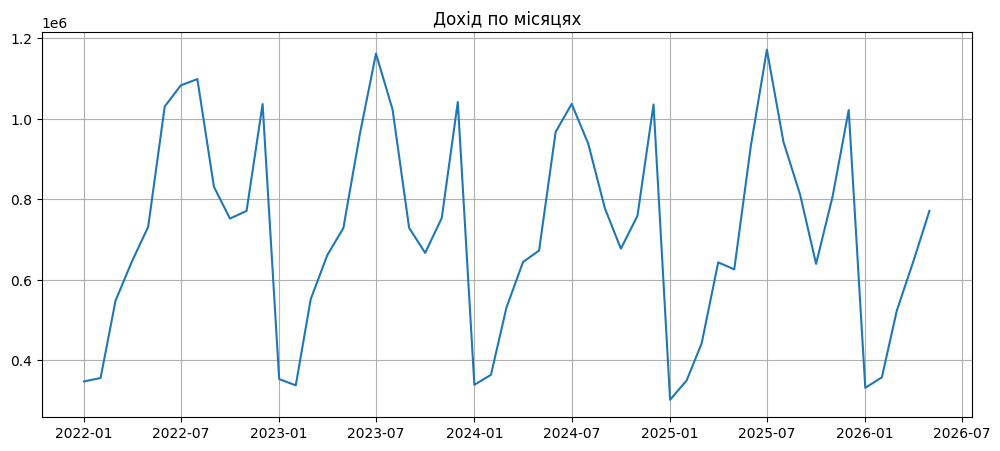

In [35]:
plt.figure(figsize=(12,5))
plt.plot(ts_income)
plt.title("Дохід по місяцях")
plt.grid(True)
plt.show()

### ADF-тест

In [36]:
result = adfuller(ts_income.dropna())

print("ADF statistic:", result[0])
print("p-value:", result[1])

ADF statistic: -1.5460282832048582
p-value: 0.5106315063165854


### Диференціювання

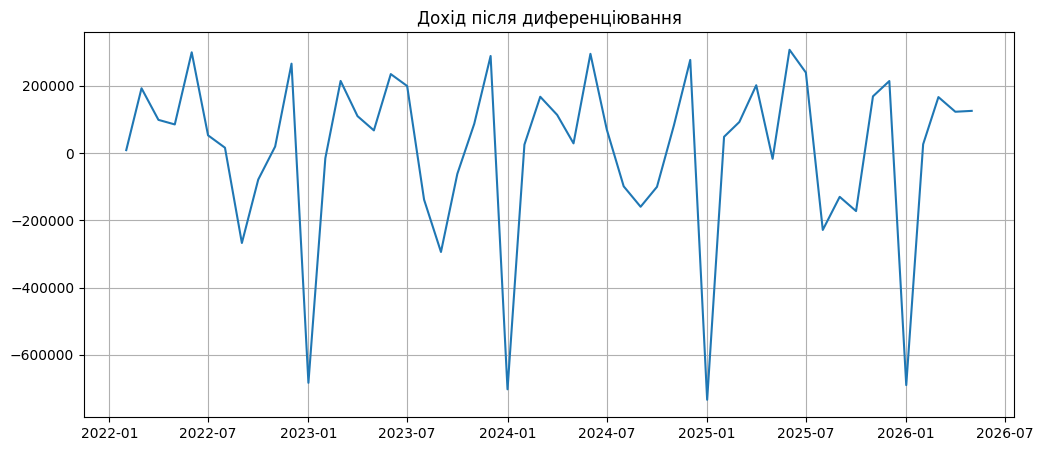

In [37]:
ts_income_diff = ts_income.diff().dropna()

plt.figure(figsize=(12,5))
plt.plot(ts_income_diff)
plt.title("Дохід після диференціювання")
plt.grid(True)
plt.show()

### ACF

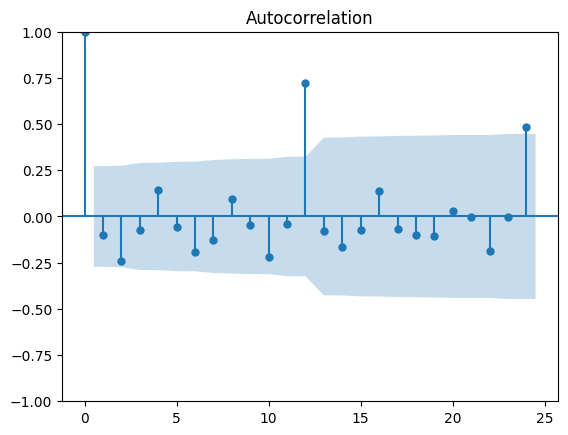

In [38]:
plot_acf(ts_income_diff, lags=24)
plt.show()

Тут чітко видно річну сезонність, тобто S=12.

### PACF

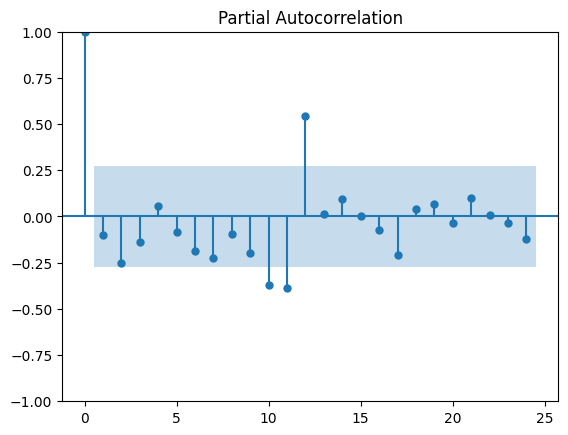

In [39]:
plot_pacf(ts_income_diff, lags=24)
plt.show()

На графіку PAKF можна спостерігати дуже сильний пік (lag=12), що свідчить про те що сезонна авторегресійна складова присутня.Тобто модель повинна враховувати сезонний AR-компонент.

In [40]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
candidates = [
    ((1, 1, 0), (1, 1, 0, 12)),
    ((1, 1, 1), (1, 1, 0, 12)),
    ((1, 1, 0), (1, 1, 1, 12)),
    ((1, 1, 1), (1, 1, 1, 12)),
    ((0, 1, 1), (1, 1, 1, 12)),
]

results = []

for order, seasonal_order in candidates:
    model_income = SARIMAX(
        ts_income,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fit = model_income.fit(disp=False)

    results.append({
        "order": order,
        "seasonal_order": seasonal_order,
        "AIC": fit.aic
    })

pd.DataFrame(results).sort_values("AIC")

,order,seasonal_order,AIC
3,"(1, 1, 1)","(1, 1, 1, 12)",645.768983
4,"(0, 1, 1)","(1, 1, 1, 12)",650.740254
0,"(1, 1, 0)","(1, 1, 0, 12)",666.211639
2,"(1, 1, 0)","(1, 1, 1, 12)",668.023681
1,"(1, 1, 1)","(1, 1, 0, 12)",668.146898


In [41]:
train = ts_income[:-12]
test = ts_income[-12:]

In [42]:
model_income = SARIMAX(
    train,
    order=(1,1,1),
    seasonal_order=(1,1,1,12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

fit = model_income.fit(disp=False)

c:\Diploma\backend\venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


In [43]:
forecast = fit.forecast(steps=12)

In [44]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(test, forecast)
rmse = mean_squared_error(test, forecast) ** 0.5
r2 = r2_score(test, forecast)

mape = (
    abs((test - forecast) / test)
).mean() * 100

print("MAE =", mae)
print("RMSE =", rmse)
print("R² =", r2)
print("MAPE =", mape)

MAE = 48725.52616101355
RMSE = 69500.75269714888
R² = 0.9208673272053569
MAPE = 6.232532662235577


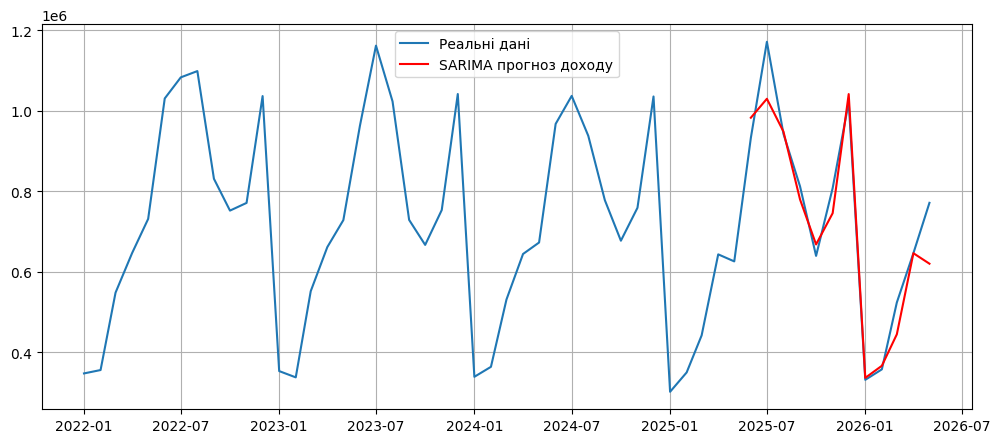

In [45]:
plt.figure(figsize=(12,5))

plt.plot(ts_income.index, ts_income, label="Реальні дані")

plt.plot(
    forecast.index,
    forecast,
    label="SARIMA прогноз доходу",
    color="red"
)

plt.legend()
plt.grid(True)
plt.show()

Прогнозування доходу модель також показала високу точність, але трохи нижчу, ніж для попиту. Це логічно, бо дохід залежить не лише від кількості записів, а й від вартості конкретних процедур.